In [1]:
import pandas as pd
import numpy as np

In [2]:
def load_energy_csv(filepath):
    # Try common encodings for Danish CSV files
    for encoding in ["utf-8", "cp1252", "latin1"]:
        try:
            # Find the actual CSV header ("Dato og tid")
            with open(filepath, "r", encoding=encoding) as f:
                lines = f.readlines()

            header_row = next(
                i for i, line in enumerate(lines)
                if line.strip().startswith("Dato og tid")
            )

            # Read the actual table
            df = pd.read_csv(
                filepath,
                sep=";",
                skiprows=header_row,
                encoding=encoding,
                skipinitialspace=True
            )

            # Remove whitespace from column names
            df.columns = df.columns.str.strip()

            # Remove empty column caused by trailing ;
            df = df.dropna(axis=1, how="all")

            # Convert timestamp column to datetime
            df["Dato og tid"] = pd.to_datetime(df["Dato og tid"])

            return df

        except UnicodeDecodeError:
            continue

    raise ValueError("Could not determine the file encoding.")

In [13]:
df = load_energy_csv("20161208_onlinedata.csv")
df = df.drop(columns=["Dato og tid"])

print(df.head())
print(df.info())

     1    2    3    4     5    6     7    8    9   10   11  12   13  14  15  \
0  599  587  270  139  2721  733 -1527 -338  554 -669  113 -18 -381  10   9   
1  557  583  271  126  2757  732 -1508 -330  505 -726  247 -17 -318  10  11   
2  527  590  241  117  2746  742 -1516 -322  473 -734  304 -19 -256  10  11   
3  512  577  213  116  2750  741 -1518 -314  483 -670  304 -18 -193  10   9   
4  492  568  198  115  2759  749 -1520 -313  503 -668  304 -18 -192  10   8   

    16    17    18  19  20  
0  190  1060  2394   0   0  
1  184  1058  2430   0   0  
2  180  1061  2427   0   0  
3  175  1060  2431   0   0  
4  170  1060  2448   0   0  
<class 'pandas.DataFrame'>
RangeIndex: 288 entries, 0 to 287
Data columns (total 20 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   1       288 non-null    int64
 1   2       288 non-null    int64
 2   3       288 non-null    int64
 3   4       288 non-null    int64
 4   5       288 non-null    int64
 5   6      

In [7]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split

In [14]:
X = df.drop("16", axis=1)
y = df["16"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
model_random_forest = RandomForestRegressor(n_estimators = 100, max_depth=2, random_state=0)
model_gradient_boost = GradientBoostingRegressor(learning_rate=0.1, n_estimators=100, max_depth=2)

model_random_forest.fit(X_train, y_train)
model_gradient_boost.fit(X_train, y_train)

score_random_forest = model_random_forest.score(X_test, y_test)
score_gradient_boost = model_gradient_boost.score(X_test, y_test)

print(f"{score_random_forest=}")
print(f"{score_gradient_boost=}")

score_random_forest = model_random_forest.score(X_train, y_train)
score_gradient_boost = model_gradient_boost.score(X_train, y_train)

print(f"{score_random_forest=}")
print(f"{score_gradient_boost=}")

score_random_forest=0.9737316279228354
score_gradient_boost=0.9962935097371787
score_random_forest=0.9791840943940818
score_gradient_boost=0.9988324478765509


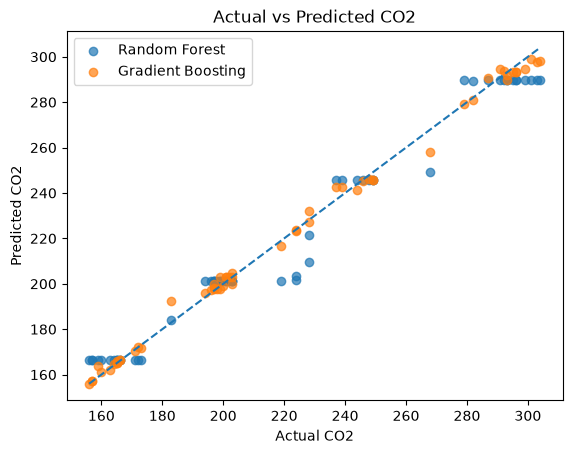

In [26]:
# Prediction
import matplotlib.pyplot as plt
pred_random_forest = model_random_forest.predict(X_test)
pred_gradient_boost = model_gradient_boost.predict(X_test)

plt.scatter(y_test, pred_random_forest, alpha=0.7, label="Random Forest")
plt.scatter(y_test, pred_gradient_boost, alpha=0.7, label="Gradient Boosting")


# Perfect-prediction line

min_val = min(y_test.min(), pred_random_forest.min(), pred_gradient_boost.min())
max_val = max(y_test.max(), pred_random_forest.max(), pred_gradient_boost.max())

plt.plot([min_val, max_val], [min_val, max_val], "--")

plt.xlabel("Actual CO2")
plt.ylabel("Predicted CO2")
plt.title("Actual vs Predicted CO2")
plt.legend()
plt.show()




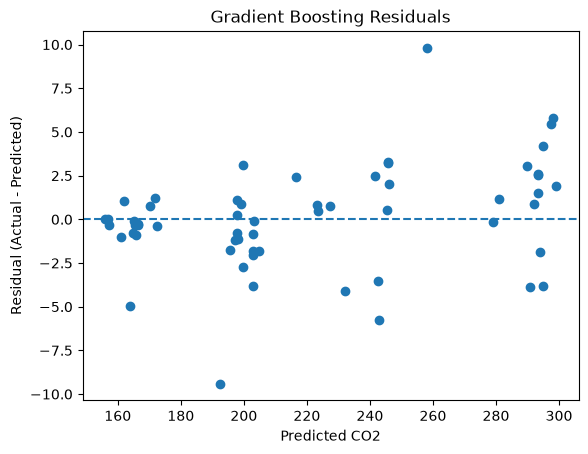

In [27]:
residuals = y_test - pred_gradient_boost

plt.scatter(pred_gradient_boost, residuals)
plt.axhline(0, linestyle="--")

plt.xlabel("Predicted CO2")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Gradient Boosting Residuals")
plt.show()

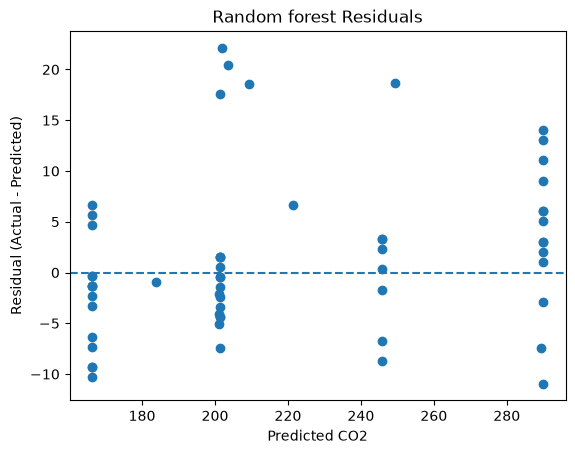

In [28]:
residuals = y_test - pred_random_forest

plt.scatter(pred_random_forest, residuals)
plt.axhline(0, linestyle="--")

plt.xlabel("Predicted CO2")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Random forest Residuals")
plt.show()

In [30]:
df = load_energy_csv("20161208_onlinedata.csv")
df = df.sort_values("Dato og tid")

X = df.drop(columns=["16", "Dato og tid"])
y = df["16"]

split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

dates_test = df["Dato og tid"].iloc[split:]

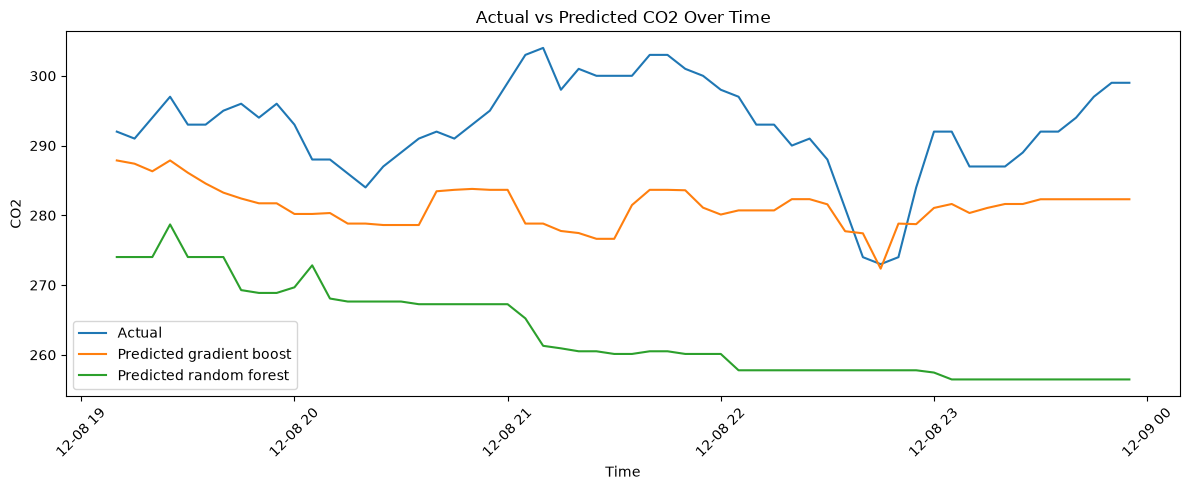

In [33]:
model_gradient_boost.fit(X_train, y_train)
model_random_forest.fit(X_train, y_train)

y_pred_grad = model_gradient_boost.predict(X_test)
y_pred_rand = model_random_forest.predict(X_test)

plt.figure(figsize=(12, 5))

plt.plot(dates_test, y_test.values, label="Actual")
plt.plot(dates_test, y_pred_grad, label="Predicted gradient boost")
plt.plot(dates_test, y_pred_rand, label="Predicted random forest")

plt.xlabel("Time")
plt.ylabel("CO2")
plt.title("Actual vs Predicted CO2 Over Time")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

for name, model in [
    ("Random Forest", model_random_forest),
    ("Gradient Boosting", model_gradient_boost)
]:
    pred = model.predict(X_test)

    print(name)
    print("R2:", r2_score(y_test, pred))
    print("MAE:", mean_absolute_error(y_test, pred))
    print("RMSE:", mean_squared_error(y_test, pred) ** 0.5)
    print()

Random Forest
R2: -19.22493507851452
MAE: 29.553245095055814
RMSE: 30.861849546866647

Gradient Boosting
R2: -2.6217641899228283
MAE: 11.6148905460976
RMSE: 13.059858358207187



Training observations: 230
Test observations: 58
Fitting 4 folds for each of 108 candidates, totalling 432 fits


0.01s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.01s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.01s - Debugger warning: It seems that frozen modules are being used, which may
0

Fitting 4 folds for each of 108 candidates, totalling 432 fits

BEST RANDOM FOREST PARAMETERS
{'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}

BEST RANDOM FOREST CV RMSE
13.493489685902603

BEST GRADIENT BOOSTING PARAMETERS
{'learning_rate': 0.05, 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 300}

BEST GRADIENT BOOSTING CV RMSE
12.132355380475676

Random Forest
------------------------------
R2:   -39.05849761724276
MAE:  41.37018438383633
RMSE: 43.43358827764729

Gradient Boosting
------------------------------
R2:   -2.2272560490409674
MAE:  11.02436829307836
RMSE: 12.328070047716423


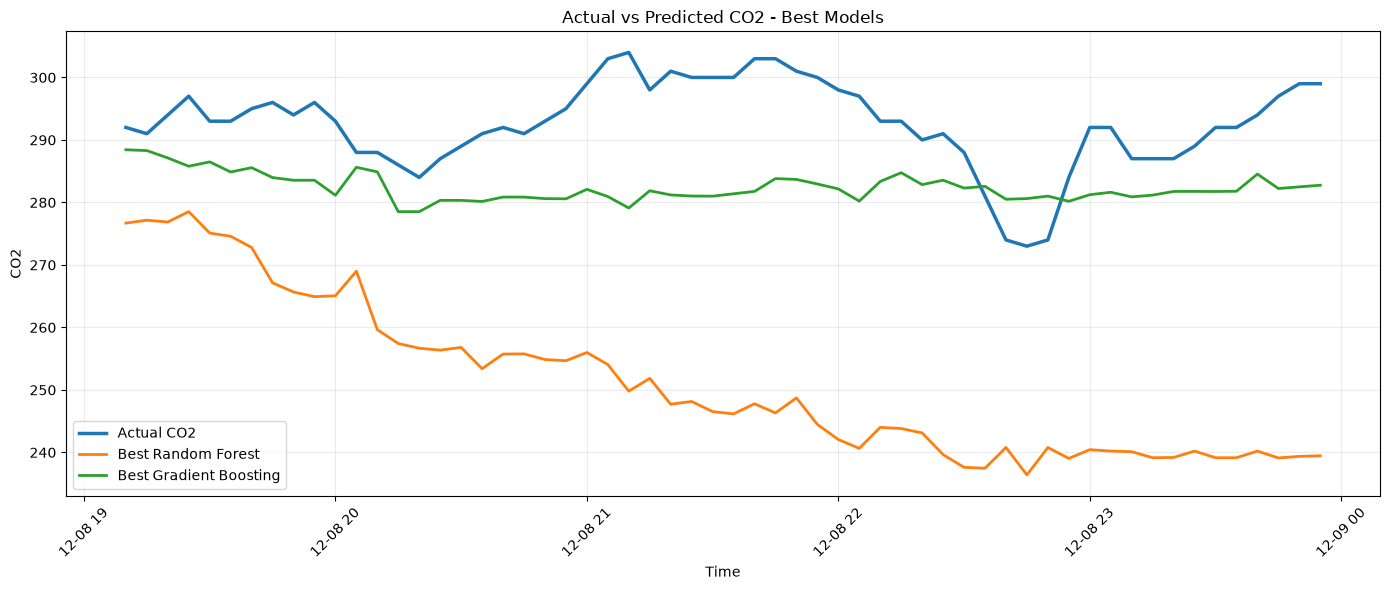

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# --------------------------------------------------
# 1. Prepare the data chronologically
# --------------------------------------------------

df = df.sort_values("Dato og tid").reset_index(drop=True)

date_col = "Dato og tid"
target_col = "16"       # CO2

X = df.drop(columns=[date_col, target_col])
y = df[target_col]

dates = df[date_col]


# --------------------------------------------------
# 2. Chronological 80/20 train-test split
# --------------------------------------------------

split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

dates_test = dates.iloc[split:]


print("Training observations:", len(X_train))
print("Test observations:", len(X_test))


# --------------------------------------------------
# 3. Time-series cross validation
# --------------------------------------------------

tscv = TimeSeriesSplit(n_splits=4)


# --------------------------------------------------
# 4. Random Forest parameter grid
# --------------------------------------------------

rf_param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", 0.7, 1.0]
}

rf_grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=rf_param_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)


# --------------------------------------------------
# 5. Gradient Boosting parameter grid
# --------------------------------------------------

gb_param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

gb_grid = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=gb_param_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)


# --------------------------------------------------
# 6. Find best parameters
# --------------------------------------------------

rf_grid.fit(X_train, y_train)
gb_grid.fit(X_train, y_train)

print("\nBEST RANDOM FOREST PARAMETERS")
print(rf_grid.best_params_)

print("\nBEST RANDOM FOREST CV RMSE")
print(-rf_grid.best_score_)


print("\nBEST GRADIENT BOOSTING PARAMETERS")
print(gb_grid.best_params_)

print("\nBEST GRADIENT BOOSTING CV RMSE")
print(-gb_grid.best_score_)


# --------------------------------------------------
# 7. Get best models
# --------------------------------------------------

best_rf = rf_grid.best_estimator_
best_gb = gb_grid.best_estimator_


# --------------------------------------------------
# 8. Predict the unseen final 20%
# --------------------------------------------------

rf_pred = best_rf.predict(X_test)
gb_pred = best_gb.predict(X_test)


# --------------------------------------------------
# 9. Evaluate models
# --------------------------------------------------

def evaluate_model(name, y_true, y_pred):
    print(f"\n{name}")
    print("-" * 30)
    print("R2:  ", r2_score(y_true, y_pred))
    print("MAE: ", mean_absolute_error(y_true, y_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_true, y_pred)))


evaluate_model("Random Forest", y_test, rf_pred)
evaluate_model("Gradient Boosting", y_test, gb_pred)


# --------------------------------------------------
# 10. Plot real CO2 vs best predictions over time
# --------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    dates_test,
    y_test.values,
    label="Actual CO2",
    linewidth=2.5
)

plt.plot(
    dates_test,
    rf_pred,
    label="Best Random Forest",
    linewidth=2
)

plt.plot(
    dates_test,
    gb_pred,
    label="Best Gradient Boosting",
    linewidth=2
)

plt.xlabel("Time")
plt.ylabel("CO2")
plt.title("Actual vs Predicted CO2 - Best Models")

plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.25)
plt.tight_layout()

plt.show()

Training observations: 230
Test observations: 58

Training Random Forest grid search...
Fitting 5 folds for each of 108 candidates, totalling 540 fits

Training Gradient Boosting grid search...
Fitting 5 folds for each of 108 candidates, totalling 540 fits

BEST RANDOM FOREST
Best parameters:
{'max_depth': 10, 'max_features': 1.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best CV RMSE:
3.37618539082316

BEST GRADIENT BOOSTING
Best parameters:
{'learning_rate': 0.1, 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 300}
Best CV RMSE:
3.158222227771094

Random Forest
----------------------------------------
R2: 0.9965736306284219
MAE: 2.141633807872736
RMSE: 2.863240981585951

Gradient Boosting
----------------------------------------
R2: 0.9972147999272333
MAE: 1.7914153706403153
RMSE: 2.581481462787423


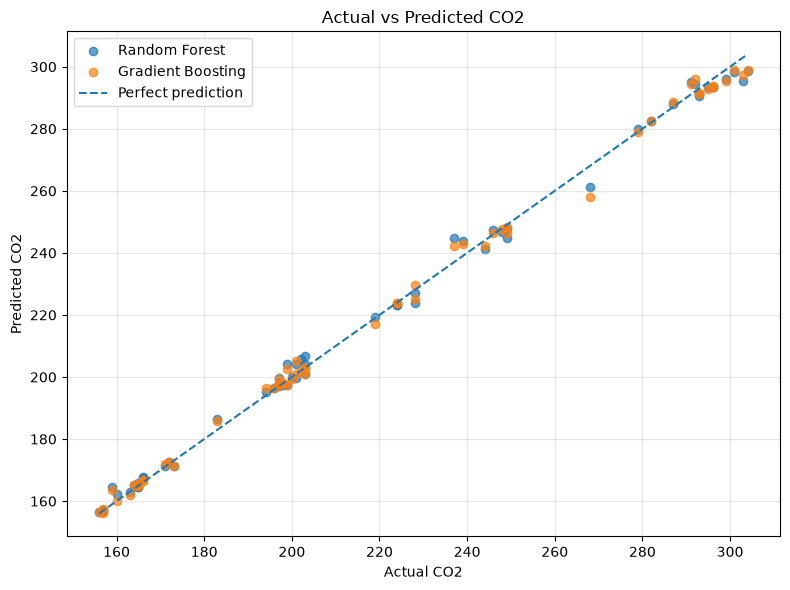

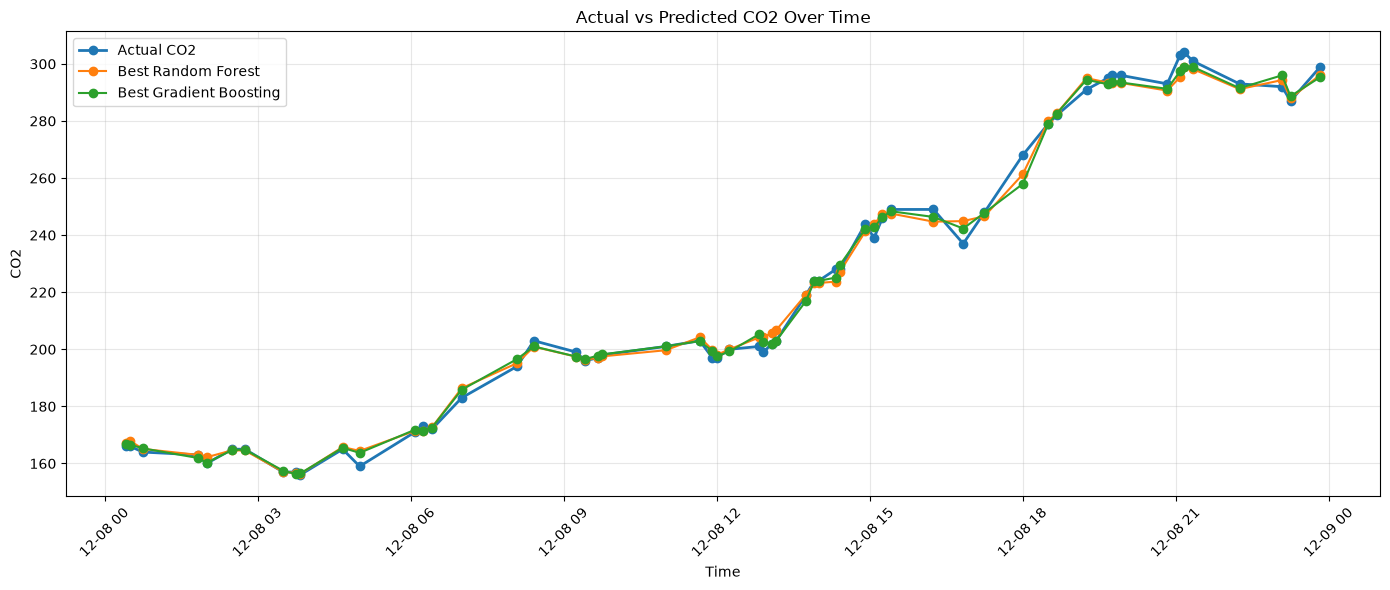


TRAIN VS TEST R2

Random Forest
Train R2: 0.999471940037786
Test R2:  0.9965736306284219

Gradient Boosting
Train R2: 0.9999974301513427
Test R2:  0.9972147999272333


In [36]:
# ============================================================
# RANDOM FOREST + GRADIENT BOOSTING
# RANDOM TRAIN/TEST SPLIT + GRID SEARCH + TIME SERIES PLOT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# --------------------------------------------------
# 1. Prepare data
# --------------------------------------------------

# Features
X = df.drop(columns=["Dato og tid", "16"])

# Target: CO2
y = df["16"]


# --------------------------------------------------
# 2. Random 80/20 train-test split
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))


# --------------------------------------------------
# 3. Random cross validation
# --------------------------------------------------

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# --------------------------------------------------
# 4. Random Forest parameter grid
# --------------------------------------------------

rf_param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", 0.7, 1.0]
}


rf_grid = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42
    ),
    param_grid=rf_param_grid,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)


# --------------------------------------------------
# 5. Gradient Boosting parameter grid
# --------------------------------------------------

gb_param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}


gb_grid = GridSearchCV(
    estimator=GradientBoostingRegressor(
        random_state=42
    ),
    param_grid=gb_param_grid,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)


# --------------------------------------------------
# 6. Run grid searches
# --------------------------------------------------

print("\nTraining Random Forest grid search...")
rf_grid.fit(X_train, y_train)

print("\nTraining Gradient Boosting grid search...")
gb_grid.fit(X_train, y_train)


# --------------------------------------------------
# 7. Show best parameters
# --------------------------------------------------

print("\n" + "=" * 50)
print("BEST RANDOM FOREST")
print("=" * 50)

print("Best parameters:")
print(rf_grid.best_params_)

print("Best CV RMSE:")
print(-rf_grid.best_score_)


print("\n" + "=" * 50)
print("BEST GRADIENT BOOSTING")
print("=" * 50)

print("Best parameters:")
print(gb_grid.best_params_)

print("Best CV RMSE:")
print(-gb_grid.best_score_)


# --------------------------------------------------
# 8. Get best models
# --------------------------------------------------

best_rf = rf_grid.best_estimator_
best_gb = gb_grid.best_estimator_


# --------------------------------------------------
# 9. Predict test data
# --------------------------------------------------

rf_pred = best_rf.predict(X_test)
gb_pred = best_gb.predict(X_test)


# --------------------------------------------------
# 10. Evaluation function
# --------------------------------------------------

def evaluate_model(name, y_true, y_pred):

    print("\n" + name)
    print("-" * 40)

    print("R2:",
          r2_score(y_true, y_pred))

    print("MAE:",
          mean_absolute_error(y_true, y_pred))

    print("RMSE:",
          np.sqrt(mean_squared_error(y_true, y_pred)))


evaluate_model(
    "Random Forest",
    y_test,
    rf_pred
)

evaluate_model(
    "Gradient Boosting",
    y_test,
    gb_pred
)


# --------------------------------------------------
# 11. Actual vs predicted scatter plot
# --------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_pred,
    alpha=0.7,
    label="Random Forest"
)

plt.scatter(
    y_test,
    gb_pred,
    alpha=0.7,
    label="Gradient Boosting"
)

min_val = min(
    y_test.min(),
    rf_pred.min(),
    gb_pred.min()
)

max_val = max(
    y_test.max(),
    rf_pred.max(),
    gb_pred.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "--",
    label="Perfect prediction"
)

plt.xlabel("Actual CO2")
plt.ylabel("Predicted CO2")
plt.title("Actual vs Predicted CO2")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


# --------------------------------------------------
# 12. Plot predictions over time
# --------------------------------------------------
#
# Because the test set was randomly selected,
# we need to recover the corresponding dates
# and sort them chronologically before plotting.
# --------------------------------------------------

test_results = pd.DataFrame({
    "Date": df.loc[X_test.index, "Dato og tid"],
    "Actual": y_test,
    "Random Forest": rf_pred,
    "Gradient Boosting": gb_pred
})

test_results = test_results.sort_values("Date")


plt.figure(figsize=(14, 6))

plt.plot(
    test_results["Date"],
    test_results["Actual"],
    marker="o",
    label="Actual CO2",
    linewidth=2
)

plt.plot(
    test_results["Date"],
    test_results["Random Forest"],
    marker="o",
    label="Best Random Forest"
)

plt.plot(
    test_results["Date"],
    test_results["Gradient Boosting"],
    marker="o",
    label="Best Gradient Boosting"
)

plt.xlabel("Time")
plt.ylabel("CO2")
plt.title("Actual vs Predicted CO2 Over Time")

plt.legend()
plt.grid(alpha=0.3)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


# --------------------------------------------------
# 13. Optional: training vs test score
# --------------------------------------------------

print("\n" + "=" * 50)
print("TRAIN VS TEST R2")
print("=" * 50)

for name, model in [
    ("Random Forest", best_rf),
    ("Gradient Boosting", best_gb)
]:

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    print(f"\n{name}")
    print("Train R2:", r2_score(y_train, train_pred))
    print("Test R2: ", r2_score(y_test, test_pred))